In [ ]:
!pip install -q datasets transformers sentence-transformers
!pip install -q opencv-python-headless scikit-image ImageHash
!pip install -q open_clip_torch gradio

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 296.7/296.7 kB 6.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 16.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.8/44.8 kB 2.2 MB/s eta 0:00:00


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import re
import unicodedata

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
data = {
    "text": [
        "Scientists publish a new study about climate change",
        "BREAKING!!! You won't believe what happened today!!!",
        "The university announced its new academic calendar",
        "SHOCKING NEWS!!! They don't want you to know this!!!",
        "The government published the annual economic report",
        "URGENT!!! Secret information finally exposed!!!",
        "Researchers released the results of a medical study",
        "MASSIVE disaster hidden by mainstream media!!!",
        "The football team won the match on Sunday",
        "Unbelievable truth revealed!!! Share before deleted!!!",
        "The company announced its quarterly financial results",
        "Breaking secret conspiracy finally revealed!!!",
        "A new public transport service started this morning",
        "They are hiding this shocking truth from everyone!!!",
        "Researchers presented their findings at the conference",
        "Share immediately!!! This information will be removed!!!"
    ],

    "label": [
        0, 1, 0, 1,
        0, 1, 0, 1,
        0, 1, 0, 1,
        0, 1, 0, 1
    ]
}

df = pd.DataFrame(data)

df.head()

,text,label
0,Scientists publish a new study about climate c...,0
1,BREAKING!!! You won't believe what happened to...,1
2,The university announced its new academic cale...,0
3,SHOCKING NEWS!!! They don't want you to know t...,1
4,The government published the annual economic r...,0


In [ ]:
print("Dataset size:", len(df))

print("\nLabel distribution:")
print(df["label"].value_counts())

df.head()

Dataset size: 16

Label distribution:
label
0    8
1    8
Name: count, dtype: int64


,text,label
0,Scientists publish a new study about climate c...,0
1,BREAKING!!! You won't believe what happened to...,1
2,The university announced its new academic cale...,0
3,SHOCKING NEWS!!! They don't want you to know t...,1
4,The government published the annual economic r...,0


In [ ]:
def clean_text(text):

    text = str(text)

    text = unicodedata.normalize("NFKC", text)

    text = text.lower()

    text = re.sub(r"http\S+|www\S+", " ", text)

    text = re.sub(r"@\w+", " ", text)

    text = re.sub(r"[^a-zA-Z0-9\s!?]", " ", text)

    text = re.sub(r"\s+", " ", text).strip()

    return text

In [ ]:
example = "BREAKING!!! Visit https://example.com @news This is SHOCKING!!!"

print("Original:")
print(example)

print("\nCleaned:")
print(clean_text(example))

Original:
BREAKING!!! Visit https://example.com @news This is SHOCKING!!!

Cleaned:
breaking!!! visit this is shocking!!!


In [ ]:
df["clean_text"] = df["text"].apply(clean_text)

df[["text", "clean_text", "label"]].head()

,text,clean_text,label
0,Scientists publish a new study about climate c...,scientists publish a new study about climate c...,0
1,BREAKING!!! You won't believe what happened to...,breaking!!! you won t believe what happened to...,1
2,The university announced its new academic cale...,the university announced its new academic cale...,0
3,SHOCKING NEWS!!! They don't want you to know t...,shocking news!!! they don t want you to know t...,1
4,The government published the annual economic r...,the government published the annual economic r...,0


In [ ]:
X = df["clean_text"]
y = df["label"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 12
Testing samples: 4


In [ ]:
tfidf = TfidfVectorizer(
    ngram_range=(1, 2),
    max_features=5000
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("TF-IDF training shape:")
print(X_train_tfidf.shape)

TF-IDF training shape:
(12, 129)


In [ ]:
text_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

text_model.fit(
    X_train_tfidf,
    y_train
)

print("Text model trained successfully!")

Text model trained successfully!


In [ ]:
y_pred = text_model.predict(X_test_tfidf)

print("Predictions:")
print(y_pred)

print("\nActual:")
print(y_test.values)

Predictions:
[0 1 0 1]

Actual:
[0 1 0 1]


In [ ]:
accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test,
    y_pred,
    zero_division=0
)

recall = recall_score(
    y_test,
    y_pred,
    zero_division=0
)

f1 = f1_score(
    y_test,
    y_pred,
    zero_division=0
)

print("Accuracy :", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall   :", round(recall, 4))
print("F1 Score :", round(f1, 4))

Accuracy : 1.0
Precision: 1.0
Recall   : 1.0
F1 Score : 1.0


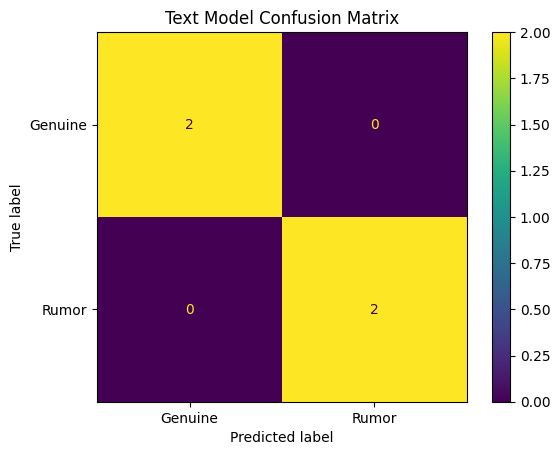

In [ ]:
cm = confusion_matrix(y_test, y_pred)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Genuine", "Rumor"]
)

display.plot()
plt.title("Text Model Confusion Matrix")
plt.show()

In [ ]:
def predict_text_rumor(text):

    cleaned = clean_text(text)

    features = tfidf.transform([cleaned])

    prediction = text_model.predict(features)[0]

    probabilities = text_model.predict_proba(features)[0]

    rumor_probability = probabilities[1]

    return {
        "prediction": int(prediction),
        "rumor_probability": float(rumor_probability)
    }

In [ ]:
claim = "SHOCKING!!! Secret truth exposed!!! Share before it is deleted!!!"

result = predict_text_rumor(claim)

print(result)

{'prediction': 1, 'rumor_probability': 0.6000782943062307}


In [ ]:
def show_text_result(text):

    result = predict_text_rumor(text)

    probability = result["rumor_probability"]

    print("=" * 50)
    print("TEXT ANALYSIS")
    print("=" * 50)

    print("Claim:")
    print(text)

    print("\nRumor Probability:")
    print(f"{probability * 100:.2f}%")

    if probability > 0.65:
        print("\nText Verdict: Suspicious / Rumor-like")

    elif probability >= 0.35:
        print("\nText Verdict: Uncertain")

    else:
        print("\nText Verdict: Likely Genuine-like")

In [ ]:
show_text_result(
    "BREAKING!!! They are hiding this shocking information from everyone!"
)

TEXT ANALYSIS
Claim:
BREAKING!!! They are hiding this shocking information from everyone!

Rumor Probability:
57.94%

Text Verdict: Uncertain
